In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from woody_filter import woody


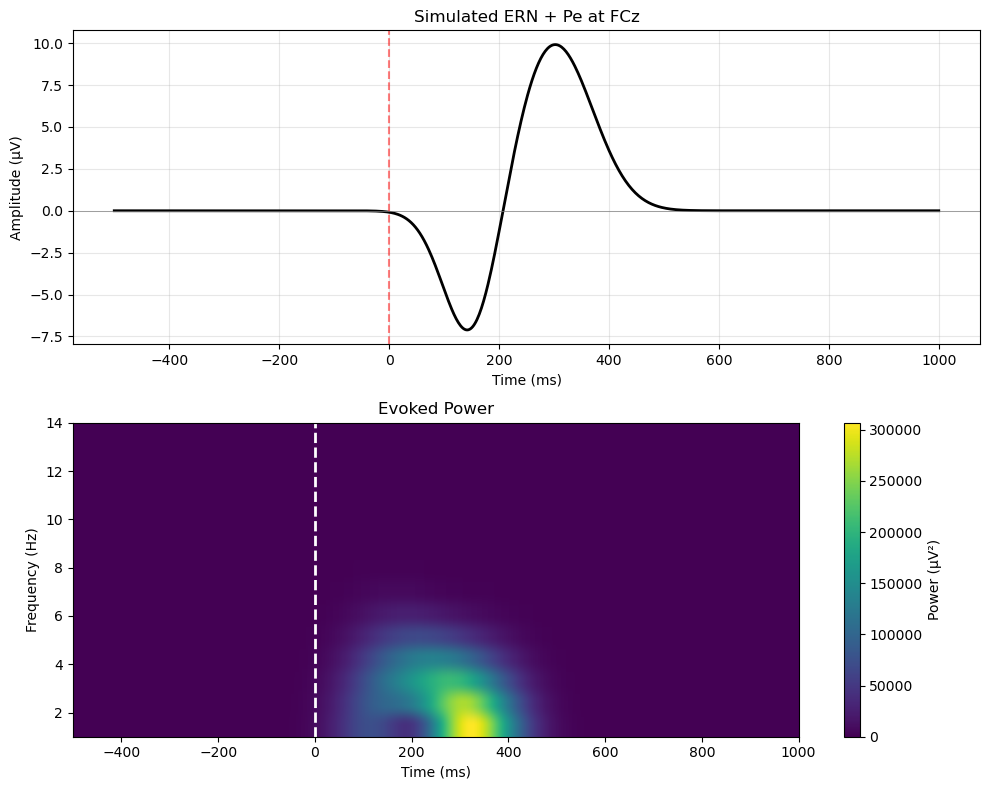

In [10]:
# ERP generation (Grand Average Waveform)
# Parameters
sfreq = 500  # Hz
tmin, tmax = -0.5, 1.0  # seconds
n_times = int((tmax - tmin) * sfreq) + 1
times = np.linspace(tmin, tmax, n_times)

# ERN parameters
ern_peak_time = 0.15  # 150ms post-error
ern_amplitude = -8  # microvolts 
ern_width = 0.05  # 50ms width

# Pe parameters
pe_peak_time = 0.3  # 300ms post-error
pe_amplitude = 10  # microvolts (positive deflection)
pe_width = 0.07  # 70ms width (broader than ERN)

# Generate ERN as Gaussian
ern = ern_amplitude * np.exp(-0.5 * ((times - ern_peak_time) / ern_width) ** 2)

# Generate Pe as Gaussian
pe = pe_amplitude * np.exp(-0.5 * ((times - pe_peak_time) / pe_width) ** 2)

# Combined ERP
erp = ern + pe

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# Morlet wavelets
tfr = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    # Shorter wavelet - max 0.5 seconds
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    
    convolved = np.convolve(erp, wavelet, mode='same')
    tfr[idx, :] = np.abs(convolved) ** 2

# Plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# ERP
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe at FCz')
ax1.grid(alpha=0.3)

# TFR
im = ax2.imshow(tfr, aspect='auto', origin='lower', 
                extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

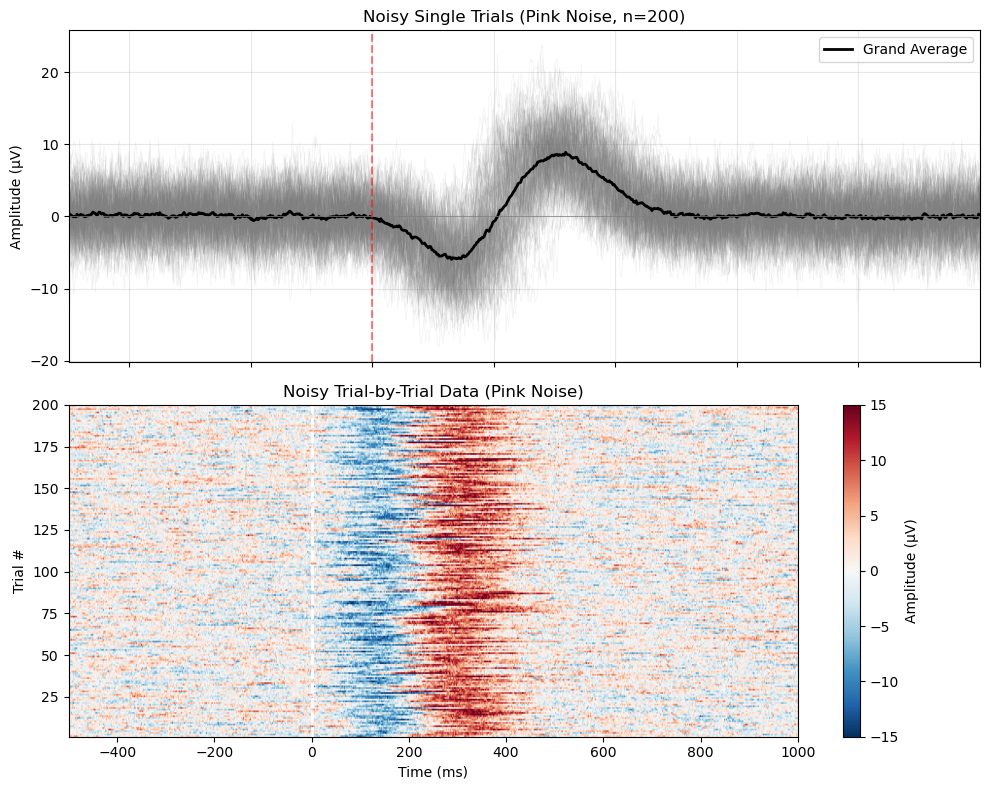

In [22]:
def generate_pink_noise(n_samples):
    """Generate pink (1/f) noise"""
    # Generate white noise
    white = np.random.randn(n_samples)
    # FFT
    fft_white = np.fft.rfft(white)
    # Create 1/f spectrum
    freqs = np.fft.rfftfreq(n_samples)
    freqs[0] = 1  # Avoid division by zero
    pink_fft = fft_white / np.sqrt(freqs)
    # Back to time domain
    pink = np.fft.irfft(pink_fft, n=n_samples)
    # Normalize
    pink = pink / np.std(pink)
    return pink

# Noise parameters
n_trials = 200
jitter_sd = 0.035  # 50ms temporal jitter
noise_amplitude = 3  # microvolts (pink noise SD)
amplitude_jitter_sd = 0.2  # 20% amplitude variability (coefficient of variation)

# Generate noisy trials
trials = np.zeros((n_trials, n_times))
true_jitters = np.zeros(n_trials)
true_ern_amplitudes = np.zeros(n_trials)
true_pe_amplitudes = np.zeros(n_trials)

for trial in range(n_trials):
    # Temporal jitter
    onset_jitter = np.random.normal(0, jitter_sd)
    onset_jitter = np.maximum(onset_jitter, -ern_peak_time)
    true_jitters[trial] = onset_jitter
    
    # Amplitude jitter (multiplicative, lognormal to keep sign consistent)
    ern_amp_factor = np.random.lognormal(0, amplitude_jitter_sd)
    pe_amp_factor = np.random.lognormal(0, amplitude_jitter_sd)
    true_ern_amplitudes[trial] = ern_amplitude * ern_amp_factor
    true_pe_amplitudes[trial] = pe_amplitude * pe_amp_factor
    
    # Generate ERN + Pe with jittered amplitudes
    ern = (ern_amplitude * ern_amp_factor) * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
    pe = (pe_amplitude * pe_amp_factor) * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
    
    # Add pink noise
    noise = generate_pink_noise(n_times) * noise_amplitude
    
    # Combine
    trials[trial, :] = ern + pe + noise

# Compute grand average
grand_avg = trials.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single trials with noise
ax1.plot(times * 1000, trials.T, 'gray', alpha=0.1, linewidth=0.5)
ax1.plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Noisy Single Trials (Pink Noise, n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all trials
im = ax2.imshow(trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-15, vmax=15)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Noisy Trial-by-Trial Data (Pink Noise)')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

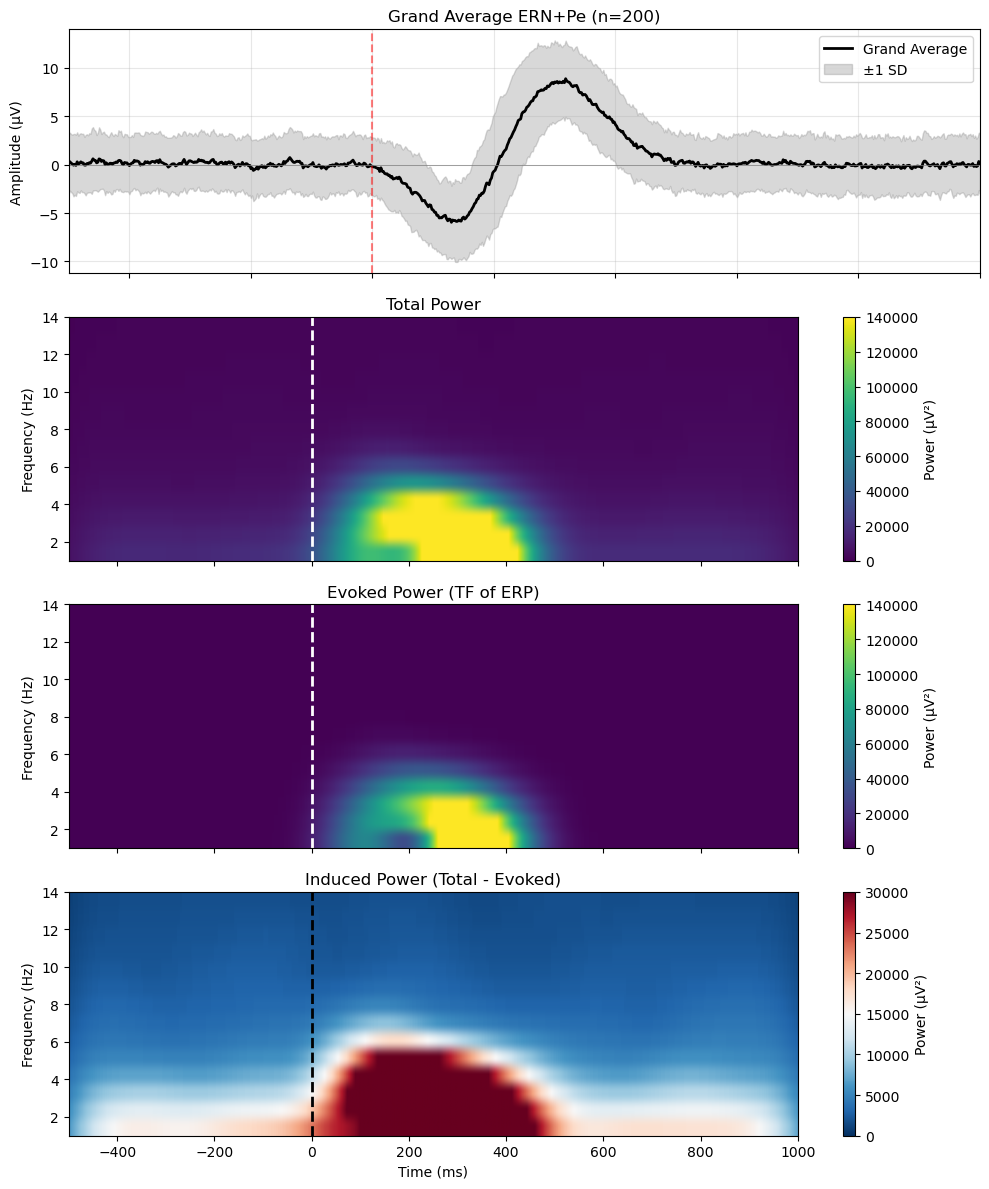

In [23]:
# Compute grand average and SD
grand_avg = trials.mean(axis=0)
sd = trials.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER (TFR of averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER = Total - Evoked
tfr_induced = tfr_total - tfr_evoked

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power
im1 = axes[1].imshow(tfr_total, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (Total - Evoked)
im3 = axes[3].imshow(tfr_induced, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

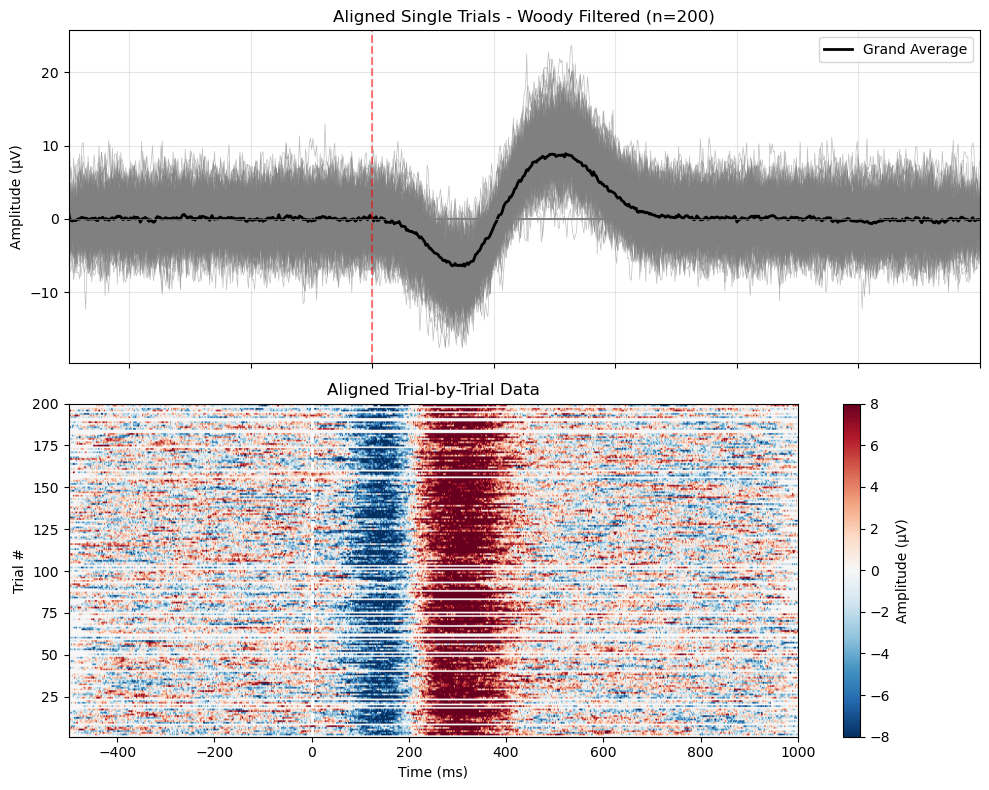

In [24]:
# Transpose to correct shape: (n_timepoints, n_trials)
trials_transposed = trials.T

# Apply iterative Woody filter
aligned_avg, detected_lags = woody(
    trials_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased'
)

# Reconstruct individual aligned trials
aligned_trials = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials[i, :] = trials[i, :]

grand_avg_aligned = aligned_trials.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single aligned trials
ax1.plot(times * 1000, aligned_trials.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Aligned Single Trials - Woody Filtered (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all aligned trials
im = ax2.imshow(aligned_trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Aligned Trial-by-Trial Data')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

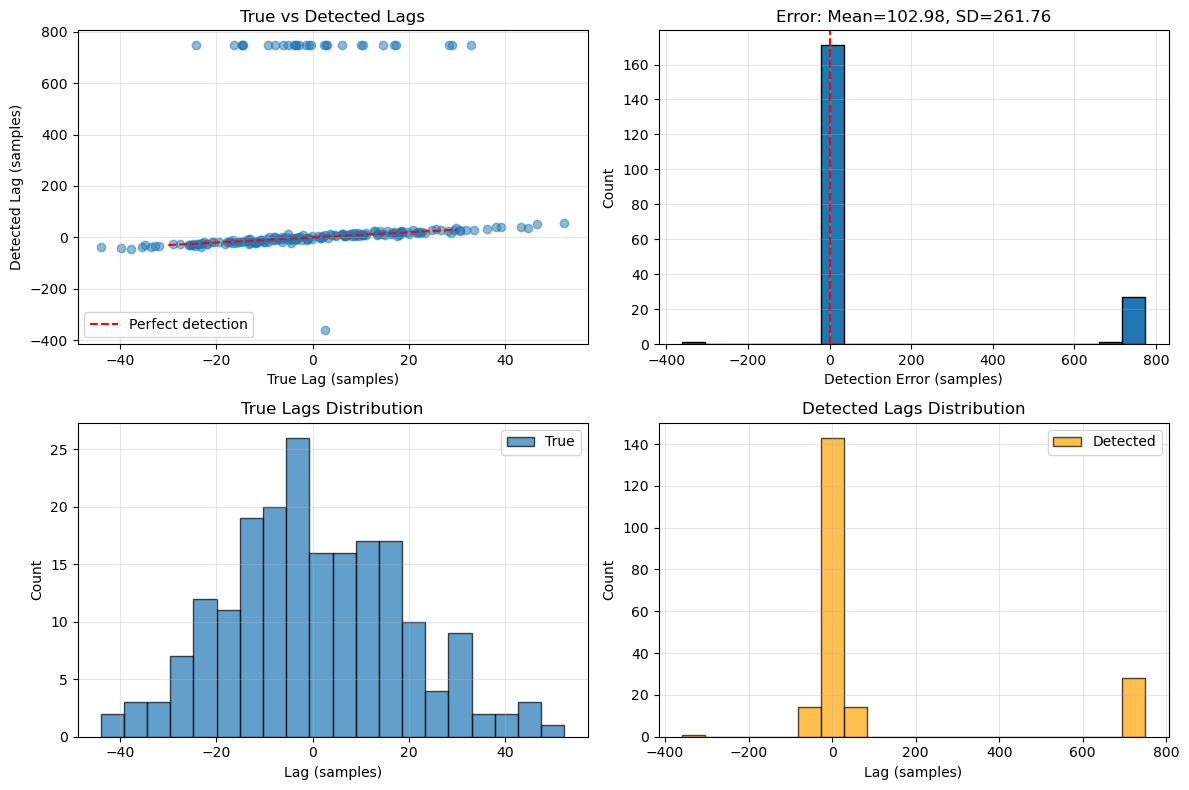

Correlation: 0.086


In [25]:
# Convert to same units
true_lags_samples = true_jitters * sfreq  # Convert seconds to samples

# Compare
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Scatter plot
axes[0, 0].scatter(true_lags_samples, detected_lags, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
error = detected_lags - true_lags_samples
axes[0, 1].hist(error, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error.mean():.2f}, SD={error.std():.2f}')
axes[0, 1].grid(alpha=0.3)

# True lags distribution
axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7, label='True')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Detected lags distribution
axes[1, 1].hist(detected_lags, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(true_lags_samples, detected_lags)[0,1]:.3f}")


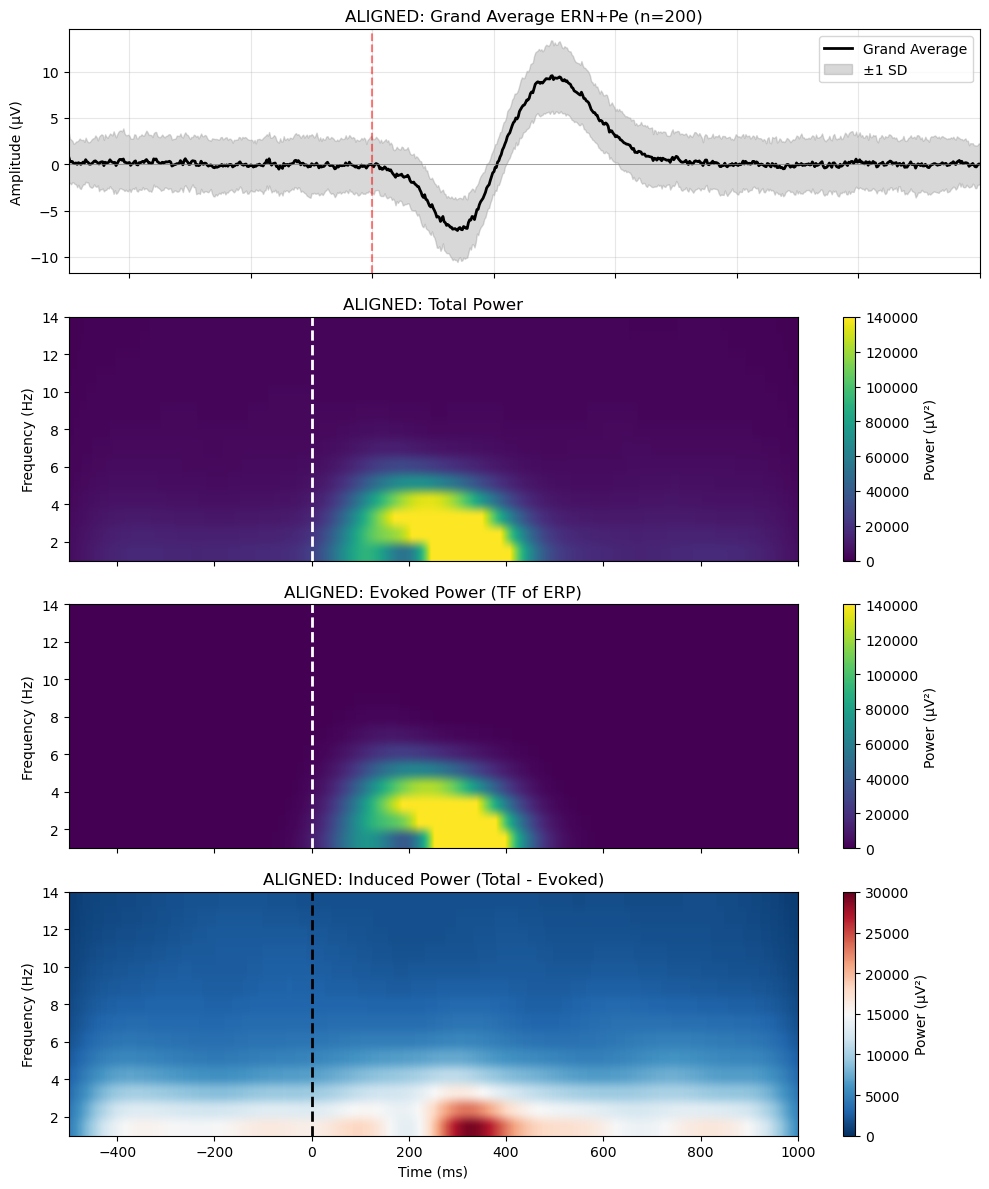

In [21]:
# Compute grand average and SD for ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# Time-Frequency Analysis on ALIGNED data
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER ALIGNED (TFR of averaged signal)
tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked_aligned[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER ALIGNED (average of single-trial TFRs)
tfr_total_aligned = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total_aligned[idx, :] += np.abs(convolved) ** 2
tfr_total_aligned /= n_trials

# INDUCED POWER ALIGNED = Total - Evoked
tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD (ALIGNED)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'ALIGNED: Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (ALIGNED)
im1 = axes[1].imshow(tfr_total_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('ALIGNED: Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power (ALIGNED)
im2 = axes[2].imshow(tfr_evoked_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('ALIGNED: Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (ALIGNED)
im3 = axes[3].imshow(tfr_induced_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('ALIGNED: Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

Run 0/1000: New best corr = 0.7182

Best correlation: 0.7185
Lag range: [-44, 56] samples
Lag std: 19.70 samples


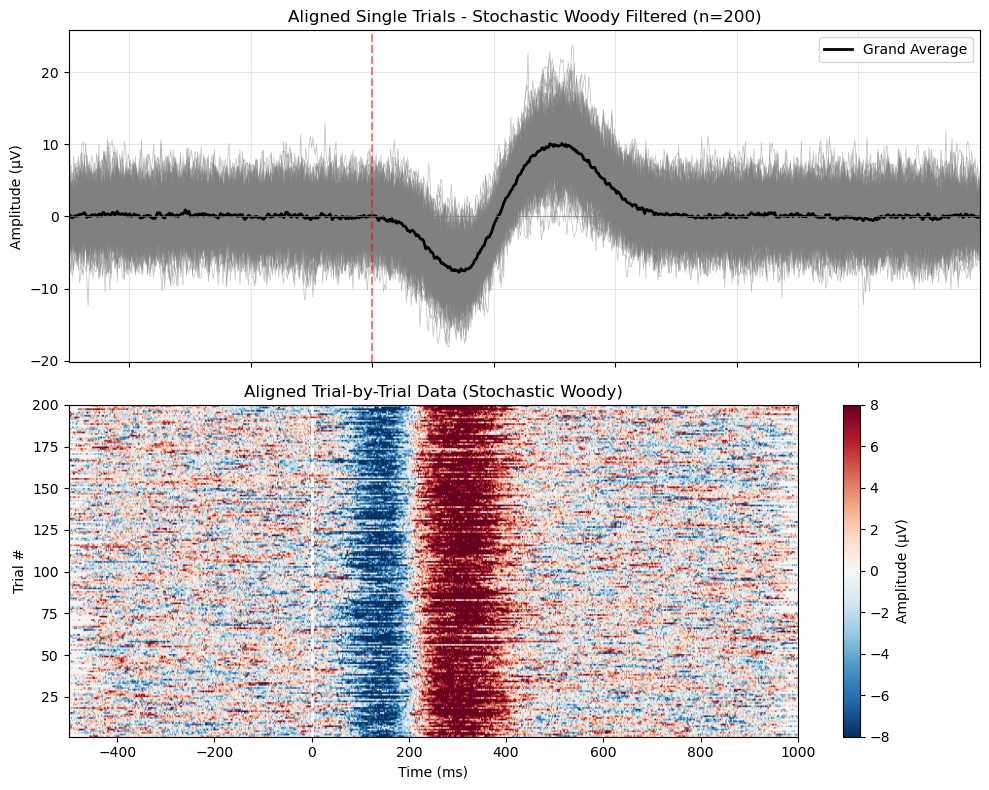

In [29]:
# Apply stochastic Woody filter
from woody_filter import woody_stochastic

aligned_avg_stoch, detected_lags_stoch, best_corr = woody_stochastic(
    trials_transposed,
    tol=0.1,
    max_it=100,
    xcorr_mthd='unbiased',
    max_lag_init=10,
    max_shift=50,
)

# Reconstruct individual aligned trials
aligned_trials_stoch = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_stoch[i]
    if lag > 0:
        aligned_trials_stoch[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_stoch[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_stoch[i, :] = trials[i, :]

grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single aligned trials
ax1.plot(times * 1000, aligned_trials_stoch.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_stoch, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Aligned Single Trials - Stochastic Woody Filtered (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all aligned trials
im = ax2.imshow(aligned_trials_stoch, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Aligned Trial-by-Trial Data (Stochastic Woody)')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

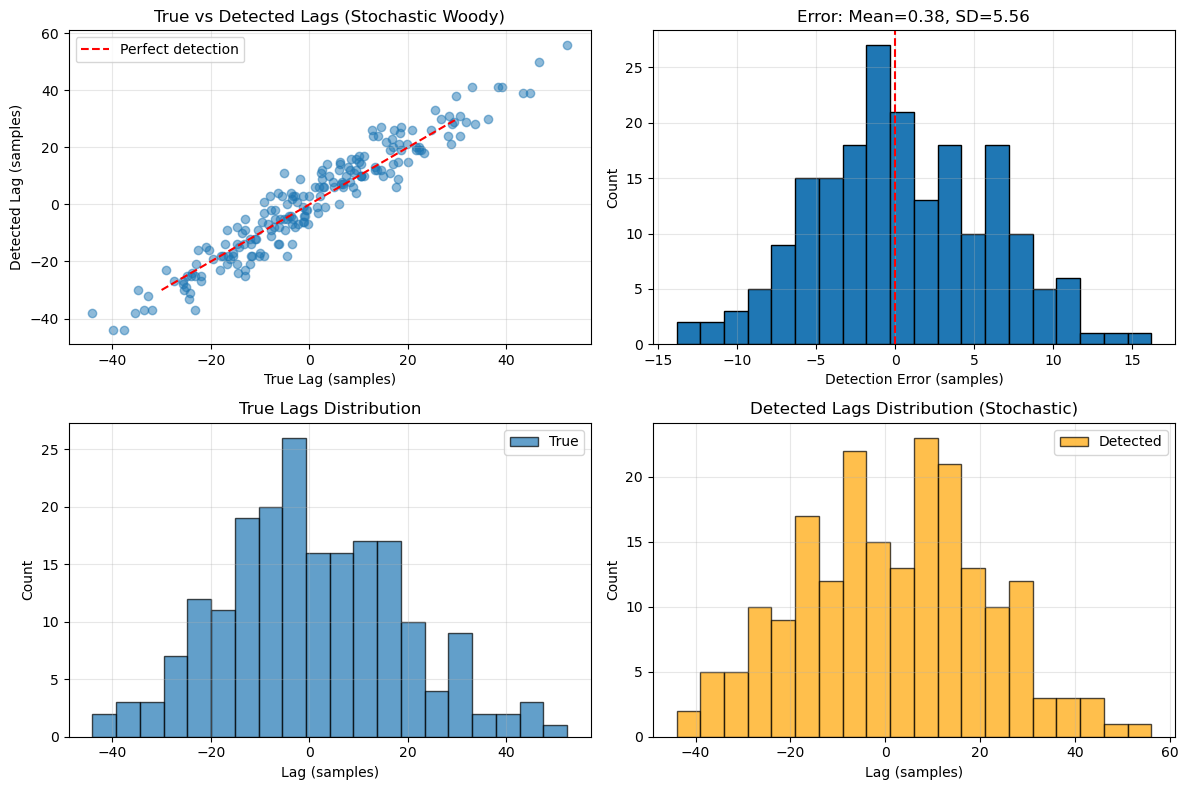

Correlation: 0.960


In [30]:
# Convert to same units
true_lags_samples = true_jitters * sfreq  # Convert seconds to samples

# Compare
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Scatter plot
axes[0, 0].scatter(true_lags_samples, detected_lags_stoch, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags (Stochastic Woody)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
error_stoch = detected_lags_stoch - true_lags_samples
axes[0, 1].hist(error_stoch, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error_stoch.mean():.2f}, SD={error_stoch.std():.2f}')
axes[0, 1].grid(alpha=0.3)

# True lags distribution
axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7, label='True')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Detected lags distribution
axes[1, 1].hist(detected_lags_stoch, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution (Stochastic)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(true_lags_samples, detected_lags_stoch)[0,1]:.3f}")

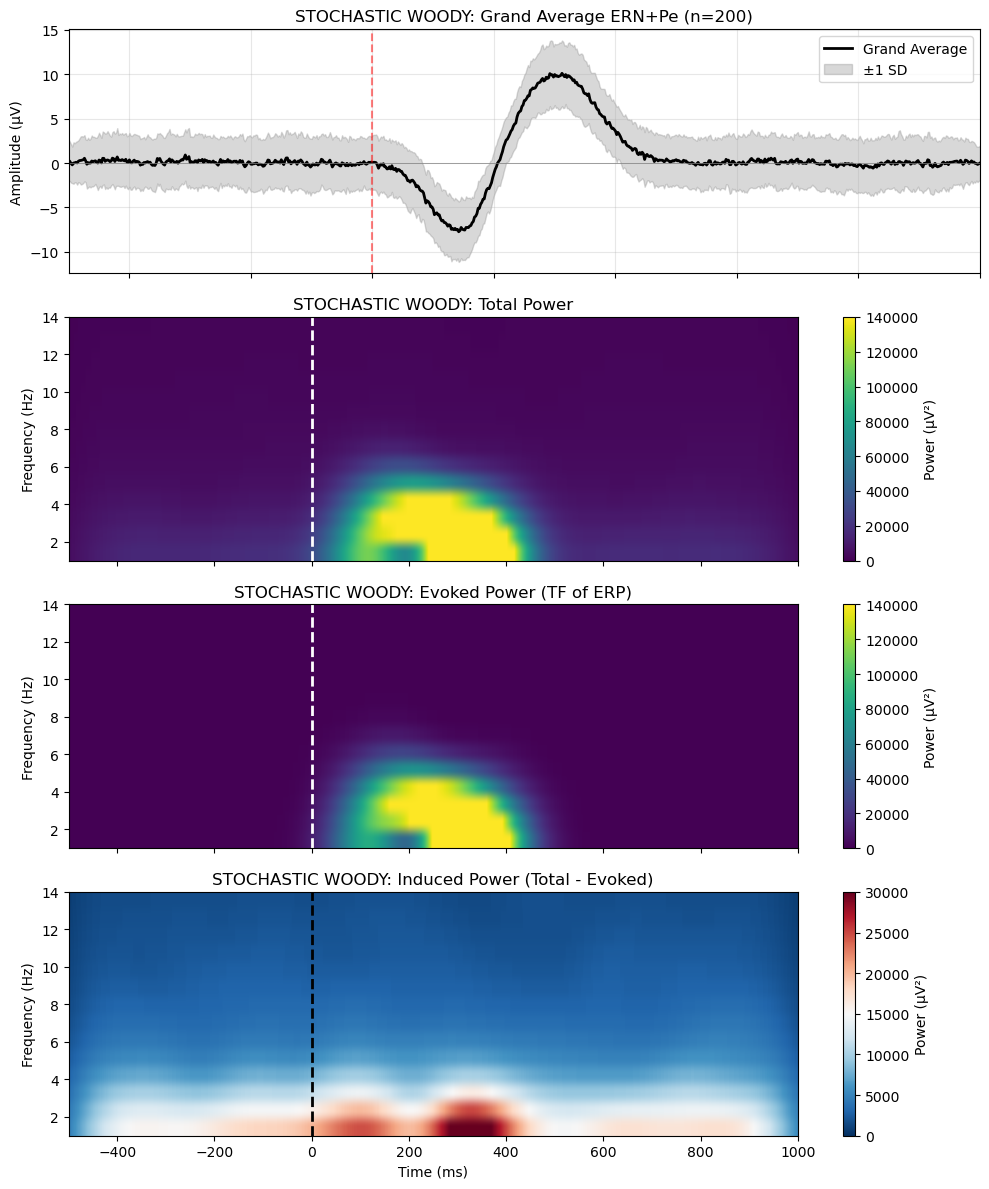

In [31]:
# Compute grand average and SD for STOCHASTIC ALIGNED trials
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)
sd_stoch = aligned_trials_stoch.std(axis=0)

# Time-Frequency Analysis on STOCHASTIC ALIGNED data
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER STOCHASTIC (TFR of averaged signal)
tfr_evoked_stoch = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_stoch, wavelet, mode='same')
    tfr_evoked_stoch[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER STOCHASTIC (average of single-trial TFRs)
tfr_total_stoch = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials_stoch[trial, :], wavelet, mode='same')
        tfr_total_stoch[idx, :] += np.abs(convolved) ** 2
tfr_total_stoch /= n_trials

# INDUCED POWER STOCHASTIC = Total - Evoked
tfr_induced_stoch = tfr_total_stoch - tfr_evoked_stoch

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD (STOCHASTIC)
axes[0].plot(times * 1000, grand_avg_stoch, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_stoch - sd_stoch, grand_avg_stoch + sd_stoch, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'STOCHASTIC WOODY: Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (STOCHASTIC)
im1 = axes[1].imshow(tfr_total_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('STOCHASTIC WOODY: Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power (STOCHASTIC)
im2 = axes[2].imshow(tfr_evoked_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('STOCHASTIC WOODY: Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (STOCHASTIC)
im3 = axes[3].imshow(tfr_induced_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('STOCHASTIC WOODY: Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

Subtracting Evoked from Epochs
[done]


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_96818/4161310390.py:8: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  trials_subtracted = epochs_subtracted.get_data()[:, 0, :]


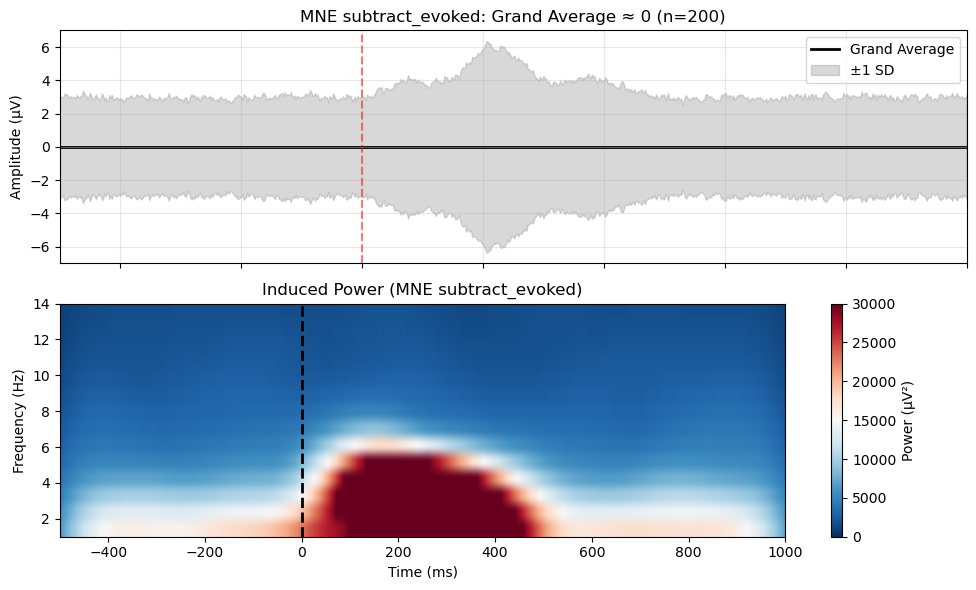

In [37]:
import mne

# Create MNE Epochs and subtract evoked
info = mne.create_info(ch_names=['FCz'], sfreq=sfreq, ch_types=['eeg'])
trials_mne = trials[:, np.newaxis, :]
epochs = mne.EpochsArray(trials_mne, info, tmin=tmin, verbose=False)
epochs_subtracted = epochs.copy().subtract_evoked()
trials_subtracted = epochs_subtracted.get_data()[:, 0, :]

# Compute grand average and SD
grand_avg_subtracted = trials_subtracted.mean(axis=0)
sd_subtracted = trials_subtracted.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

# INDUCED POWER via subtract_evoked (TFR of residuals)
tfr_induced_subtract_evoked = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_subtracted[trial, :], wavelet, mode='same')
        tfr_induced_subtract_evoked[idx, :] += np.abs(convolved) ** 2
tfr_induced_subtract_evoked /= n_trials

# Plot
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Grand average ERP with SD (after subtract_evoked)
axes[0].plot(times * 1000, grand_avg_subtracted, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_subtracted - sd_subtracted, grand_avg_subtracted + sd_subtracted, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'MNE subtract_evoked: Grand Average ≈ 0 (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Induced Power
im = axes[1].imshow(tfr_induced_subtract_evoked, aspect='auto', origin='lower', 
                    extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                    cmap='RdBu_r', vmin=0, vmax=30000)
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Induced Power (MNE subtract_evoked)')
plt.colorbar(im, ax=axes[1], label='Power (µV²)')

plt.tight_layout()
plt.show()

Subtracting Evoked from Epochs
[done]


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_96818/254207367.py:29: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  trials_aligned_subtracted = epochs_aligned_subtracted.get_data()[:, 0, :]


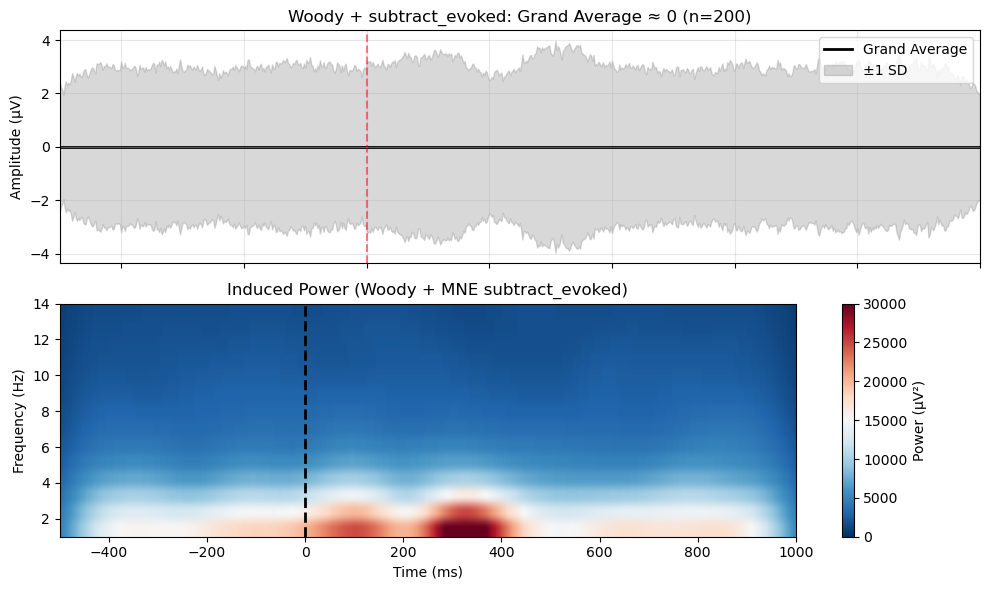

In [40]:
import mne

# First apply Woody filter to align trials
aligned_avg_woody, detected_lags_woody = woody(
    trials_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=50
)

# Reconstruct aligned trials
aligned_trials_woody = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_woody[i]
    if lag > 0:
        aligned_trials_woody[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_woody[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_woody[i, :] = trials[i, :]

# Now create MNE Epochs from ALIGNED trials and subtract evoked
info = mne.create_info(ch_names=['FCz'], sfreq=sfreq, ch_types=['eeg'])
aligned_mne = aligned_trials_woody[:, np.newaxis, :]
epochs_aligned = mne.EpochsArray(aligned_mne, info, tmin=tmin, verbose=False)
epochs_aligned_subtracted = epochs_aligned.copy().subtract_evoked()
trials_aligned_subtracted = epochs_aligned_subtracted.get_data()[:, 0, :]

# Compute grand average and SD
grand_avg_aligned_subtracted = trials_aligned_subtracted.mean(axis=0)
sd_aligned_subtracted = trials_aligned_subtracted.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

# INDUCED POWER via Woody + subtract_evoked
tfr_induced_woody_subtract = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_aligned_subtracted[trial, :], wavelet, mode='same')
        tfr_induced_woody_subtract[idx, :] += np.abs(convolved) ** 2
tfr_induced_woody_subtract /= n_trials

# Plot
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Grand average ERP with SD (after Woody + subtract_evoked)
axes[0].plot(times * 1000, grand_avg_aligned_subtracted, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_aligned_subtracted - sd_aligned_subtracted, 
                      grand_avg_aligned_subtracted + sd_aligned_subtracted, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Woody + subtract_evoked: Grand Average ≈ 0 (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Induced Power
im = axes[1].imshow(tfr_induced_woody_subtract, aspect='auto', origin='lower', 
                    extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                    cmap='RdBu_r', vmin=0, vmax=30000)
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Induced Power (Woody + MNE subtract_evoked)')
plt.colorbar(im, ax=axes[1], label='Power (µV²)')

plt.tight_layout()
plt.show()

Run 0/1000: New best corr = 0.7182

Best correlation: 0.7185
Lag range: [-45, 53] samples
Lag std: 19.61 samples
Subtracting Evoked from Epochs
[done]


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_96818/3361349120.py:29: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  trials_aligned_stoch_subtracted = epochs_aligned_stoch_subtracted.get_data()[:, 0, :]


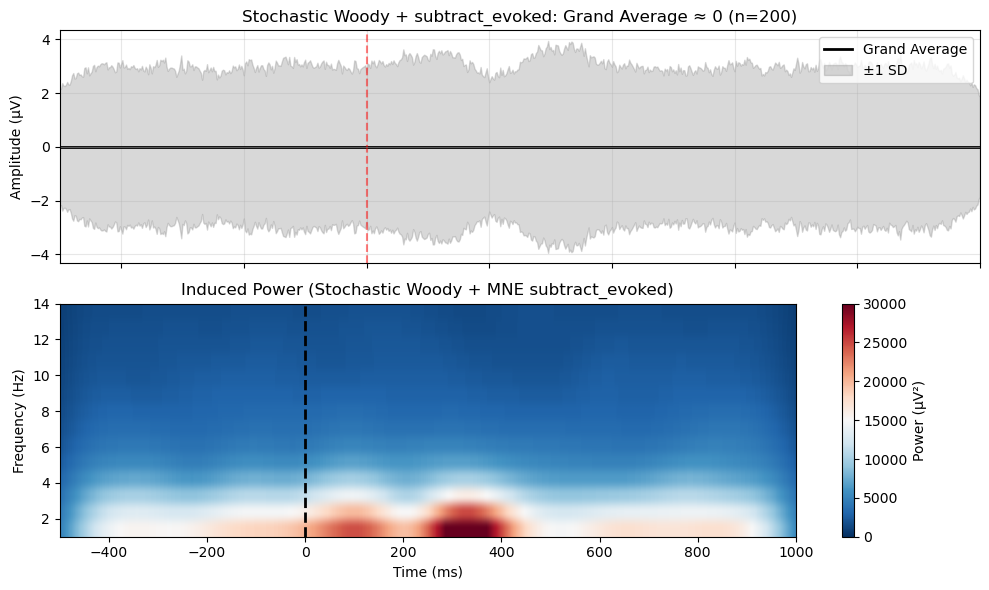

In [41]:
import mne

# First apply Stochastic Woody filter to align trials
aligned_avg_stoch, detected_lags_stoch, best_corr = woody_stochastic(
    trials_transposed,
    tol=0.1,
    max_it=100,
    xcorr_mthd='unbiased',
    max_lag_init=10,
    max_shift=50,
)

# Reconstruct aligned trials
aligned_trials_stoch = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_stoch[i]
    if lag > 0:
        aligned_trials_stoch[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_stoch[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_stoch[i, :] = trials[i, :]

# Now create MNE Epochs from ALIGNED trials and subtract evoked
info = mne.create_info(ch_names=['FCz'], sfreq=sfreq, ch_types=['eeg'])
aligned_mne_stoch = aligned_trials_stoch[:, np.newaxis, :]
epochs_aligned_stoch = mne.EpochsArray(aligned_mne_stoch, info, tmin=tmin, verbose=False)
epochs_aligned_stoch_subtracted = epochs_aligned_stoch.copy().subtract_evoked()
trials_aligned_stoch_subtracted = epochs_aligned_stoch_subtracted.get_data()[:, 0, :]

# Compute grand average and SD
grand_avg_stoch_subtracted = trials_aligned_stoch_subtracted.mean(axis=0)
sd_stoch_subtracted = trials_aligned_stoch_subtracted.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

# INDUCED POWER via Stochastic Woody + subtract_evoked
tfr_induced_stoch_subtract = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_aligned_stoch_subtracted[trial, :], wavelet, mode='same')
        tfr_induced_stoch_subtract[idx, :] += np.abs(convolved) ** 2
tfr_induced_stoch_subtract /= n_trials

# Plot
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Grand average ERP with SD (after Stochastic Woody + subtract_evoked)
axes[0].plot(times * 1000, grand_avg_stoch_subtracted, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_stoch_subtracted - sd_stoch_subtracted, 
                      grand_avg_stoch_subtracted + sd_stoch_subtracted, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Stochastic Woody + subtract_evoked: Grand Average ≈ 0 (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Induced Power
im = axes[1].imshow(tfr_induced_stoch_subtract, aspect='auto', origin='lower', 
                    extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                    cmap='RdBu_r', vmin=0, vmax=30000)
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Induced Power (Stochastic Woody + MNE subtract_evoked)')
plt.colorbar(im, ax=axes[1], label='Power (µV²)')

plt.tight_layout()
plt.show()

In [38]:
# def generate_pink_noise(n_samples):
#     """Generate pink (1/f) noise"""
#     white = np.random.randn(n_samples)
#     fft_white = np.fft.rfft(white)
#     freqs = np.fft.rfftfreq(n_samples)
#     freqs[0] = 1
#     pink_fft = fft_white / np.sqrt(freqs)
#     pink = np.fft.irfft(pink_fft, n=n_samples)
#     pink = pink / np.std(pink)
#     return pink

# # First compute signal RMS
# signal_rms = np.sqrt(np.mean((ern_amplitude**2 + pe_amplitude**2) / 2))

# # Target SNR values
# target_snr_db = np.linspace(-20, 10, 20)
# snr_values = []
# correlations = []
# biases = []
# n_trials = 100
# jitter_sd = 0.05

# # Store trials for later TFR plotting
# stored_trials = {}

# # Compute correlations and biases for all SNR levels
# for snr_db in target_snr_db:
#     snr_linear = 10**(snr_db / 20)
#     noise_amp = signal_rms / snr_linear
    
#     trials_signal = np.zeros((n_trials, n_times))
#     trials_noisy = np.zeros((n_trials, n_times))
#     true_jitters = np.zeros(n_trials)
    
#     for trial in range(n_trials):
#         onset_jitter = np.random.normal(0, jitter_sd)
#         onset_jitter = np.maximum(onset_jitter, -ern_peak_time)
#         true_jitters[trial] = onset_jitter
        
#         ern = ern_amplitude * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
#         pe = pe_amplitude * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
#         signal_trial = ern + pe
        
#         noise = generate_pink_noise(n_times) * noise_amp
        
#         trials_signal[trial, :] = signal_trial
#         trials_noisy[trial, :] = signal_trial + noise
    
#     snr_values.append(snr_db)
    
#     # Store trials for TFR plotting
#     stored_trials[snr_db] = trials_noisy.copy()
    
#     # Transpose to correct shape: (n_timepoints, n_trials)
#     trials_T = trials_noisy.T
    
#     # Apply proper Woody filter WITH MAX_SHIFT
#     aligned_avg, detected_lags = woody(
#         trials_T,
#         tol=0.1,
#         max_it=100,
#         est_mthd='woody',
#         xcorr_mthd='unbiased',
#         max_shift=50  # ADDED THIS!
#     )
    
#     true_lags_samples = true_jitters * sfreq
#     corr = np.corrcoef(true_lags_samples, detected_lags)[0, 1]
#     correlations.append(corr)
    
#     # Compute bias
#     bias = (detected_lags - true_lags_samples).mean()
#     biases.append(bias)

# # Create combined figure - 5 rows for 6 TFR plots in 3 columns
# fig = plt.figure(figsize=(16, 20))
# gs = fig.add_gridspec(5, 3, hspace=0.35, wspace=0.4, height_ratios=[1, 1, 1.2, 1.2, 1.2])

# # Top row: Correlation plot
# ax_corr = fig.add_subplot(gs[0, :])
# ax_corr.plot(snr_values, correlations, 'o-', linewidth=2, markersize=8, color='steelblue')
# ax_corr.axhline(0.9, color='r', linestyle='--', alpha=0.5, label='r = 0.9')
# ax_corr.axhline(0.7, color='orange', linestyle='--', alpha=0.5, label='r = 0.7')
# ax_corr.axvline(0, color='gray', linestyle=':', alpha=0.5)
# ax_corr.set_xlabel('SNR (dB)')
# ax_corr.set_ylabel('Correlation')
# ax_corr.set_title('Woody Filter Performance: Correlation (True vs Detected Lags)')
# ax_corr.grid(alpha=0.3)
# ax_corr.legend()
# ax_corr.set_ylim(0, 1.05)
# ax_corr.set_xlim(-22, 12)

# # Second row: Bias plot
# ax_bias = fig.add_subplot(gs[1, :])
# ax_bias.plot(snr_values, biases, 'o-', linewidth=2, markersize=8, color='darkgreen')
# ax_bias.axhline(0, color='r', linestyle='--', alpha=0.5, label='No bias')
# ax_bias.axvline(0, color='gray', linestyle=':', alpha=0.5)
# ax_bias.set_xlabel('SNR (dB)')
# ax_bias.set_ylabel('Bias (samples)')
# ax_bias.set_title('Woody Filter Performance: Bias (Mean Detected - True Lag)')
# ax_bias.grid(alpha=0.3)
# ax_bias.legend()
# ax_bias.set_xlim(-22, 12)

# # Bottom: Baseline-corrected TFR plots at selected SNR levels (6 plots in 2x3 grid)
# snr_levels_to_plot = [-20, -10, -5, 0, 5, 10]
# freqs = np.arange(1, 15, 1)
# n_cycles = freqs / 2.0

# # Baseline window
# baseline_window = (times >= -0.3) & (times < 0)

# for idx, target_snr in enumerate(snr_levels_to_plot):
#     row = 2 + idx // 3  # 3 columns per row
#     col = idx % 3
#     ax = fig.add_subplot(gs[row, col])
    
#     # Find closest SNR value that was actually computed
#     snr_array = np.array(snr_values)
#     closest_idx = np.argmin(np.abs(snr_array - target_snr))
#     snr_db = snr_values[closest_idx]
    
#     # Retrieve stored trials from the first loop
#     trials_noisy = stored_trials[snr_db]
    
#     # Transpose to correct shape: (n_timepoints, n_trials)
#     trials_T = trials_noisy.T
    
#     # Apply proper Woody filter
#     aligned_avg, detected_lags = woody(
#         trials_T,
#         tol=0.1,
#         max_it=100,
#         est_mthd='woody',
#         xcorr_mthd='unbiased',
#         max_shift=50
#     )
    
#     # Reconstruct individual aligned trials
#     aligned_trials = np.zeros_like(trials_noisy)
#     for i in range(n_trials):
#         lag = detected_lags[i]
#         if lag > 0:
#             # Positive lag: trial is delayed, shift left
#             aligned_trials[i, :] = np.concatenate([trials_noisy[i, lag:], np.zeros(lag)])
#         elif lag < 0:
#             # Negative lag: trial is early, shift right
#             aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials_noisy[i, :lag]])
#         else:
#             aligned_trials[i, :] = trials_noisy[i, :]
    
#     grand_avg_aligned = aligned_trials.mean(axis=0)
    
#     # Compute TFRs
#     tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
#     for freq_idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
#         wavelet_duration = min(3 * n_cycle / freq, 0.5)
#         wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
#         wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
#         convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
#         tfr_evoked_aligned[freq_idx, :] = np.abs(convolved) ** 2
    
#     tfr_total_aligned = np.zeros((len(freqs), len(times)))
#     for trial in range(n_trials):
#         for freq_idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
#             wavelet_duration = min(3 * n_cycle / freq, 0.5)
#             wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
#             wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
#             convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
#             tfr_total_aligned[freq_idx, :] += np.abs(convolved) ** 2
#     tfr_total_aligned /= n_trials
    
#     tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned
    
#     # Baseline correction (percent change)
#     baseline_mean = tfr_induced_aligned[:, baseline_window].mean(axis=1, keepdims=True)
#     tfr_induced_baseline = (tfr_induced_aligned - baseline_mean) / baseline_mean * 100
    
#     # Plot
#     im = ax.imshow(tfr_induced_baseline, aspect='auto', origin='lower',
#                    extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
#                    cmap='RdBu_r', vmin=-100, vmax=100)
#     ax.axvline(0, color='black', linestyle='--', linewidth=2)
#     ax.set_title(f'SNR = {snr_db:.1f} dB')
#     ax.set_ylabel('Frequency (Hz)')
    
#     if row == 4:  # Bottom row
#         ax.set_xlabel('Time (ms)')
    
#     # Add colorbar
#     plt.colorbar(im, ax=ax, label='% change')

# plt.suptitle('Woody Filter Performance and Baseline-Corrected Induced Power', fontsize=16, y=0.995)
# plt.show()

In [39]:
# # First compute signal RMS
# signal_rms = np.sqrt(np.mean((ern_amplitude**2 + pe_amplitude**2) / 2))

# # Selected SNR levels to plot (same as aligned version)
# snr_levels_to_plot = [-20, -10, -5, 0, 5, 10]
# freqs = np.arange(1, 15, 1)
# n_cycles = freqs / 2.0
# n_trials = 100
# jitter_sd = 0.05

# # Baseline window
# baseline_window = (times >= -0.3) & (times < 0)

# # Create figure
# fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
# axes = axes.flatten()

# for idx, snr_db in enumerate(snr_levels_to_plot):
#     ax = axes[idx]
    
#     # Calculate noise amplitude
#     snr_linear = 10**(snr_db / 20)
#     noise_amp = signal_rms / snr_linear
    
#     # Generate trials WITHOUT alignment
#     trials_noisy = np.zeros((n_trials, n_times))
#     true_jitters = np.zeros(n_trials)
    
#     for trial in range(n_trials):
#         onset_jitter = np.random.normal(0, jitter_sd)
#         onset_jitter = np.maximum(onset_jitter, -ern_peak_time)
#         true_jitters[trial] = onset_jitter
        
#         ern = ern_amplitude * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
#         pe = pe_amplitude * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
#         noise = generate_pink_noise(n_times) * noise_amp
        
#         trials_noisy[trial, :] = ern + pe + noise
    
#     # NO Woody filtering - use raw trials
#     grand_avg_raw = trials_noisy.mean(axis=0)
    
#     # Compute TFRs
#     tfr_evoked_raw = np.zeros((len(freqs), len(times)))
#     for freq_idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
#         wavelet_duration = min(3 * n_cycle / freq, 0.5)
#         wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
#         wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
#         convolved = np.convolve(grand_avg_raw, wavelet, mode='same')
#         tfr_evoked_raw[freq_idx, :] = np.abs(convolved) ** 2
    
#     tfr_total_raw = np.zeros((len(freqs), len(times)))
#     for trial in range(n_trials):
#         for freq_idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
#             wavelet_duration = min(3 * n_cycle / freq, 0.5)
#             wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
#             wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
#             convolved = np.convolve(trials_noisy[trial, :], wavelet, mode='same')
#             tfr_total_raw[freq_idx, :] += np.abs(convolved) ** 2
#     tfr_total_raw /= n_trials
    
#     tfr_induced_raw = tfr_total_raw - tfr_evoked_raw
    
#     # Baseline correction (percent change)
#     baseline_mean = tfr_induced_raw[:, baseline_window].mean(axis=1, keepdims=True)
#     tfr_induced_baseline = (tfr_induced_raw - baseline_mean) / baseline_mean * 100
    
#     # Plot
#     im = ax.imshow(tfr_induced_baseline, aspect='auto', origin='lower',
#                    extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
#                    cmap='RdBu_r', vmin=-100, vmax=100)
#     ax.axvline(0, color='black', linestyle='--', linewidth=2)
#     ax.set_title(f'SNR = {snr_db} dB')
#     ax.set_ylabel('Frequency (Hz)')
    
#     if idx >= 3:  # Bottom row
#         ax.set_xlabel('Time (ms)')
    
#     # Add colorbar
#     plt.colorbar(im, ax=ax, label='% change')

# plt.suptitle('NON-ALIGNED: Baseline-Corrected Induced Power at Different SNR Levels', fontsize=14, y=0.995)
# plt.tight_layout()
# plt.show()